In [1]:
import pandas as pd
df = pd.read_csv("data/Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.shape

(7043, 21)

In [3]:
df.columns


Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [4]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [5]:
churn_rate = (df["Churn"].value_counts()["Yes"] / len(df)) * 100
print(round(churn_rate, 2))

26.54


In [6]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [7]:
churn_by_contract = (
    df.groupby("Contract")["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)
print(churn_by_contract)

Contract        Churn
Month-to-month  No       57.29
                Yes      42.71
One year        No       88.73
                Yes      11.27
Two year        No       97.17
                Yes       2.83
Name: proportion, dtype: float64


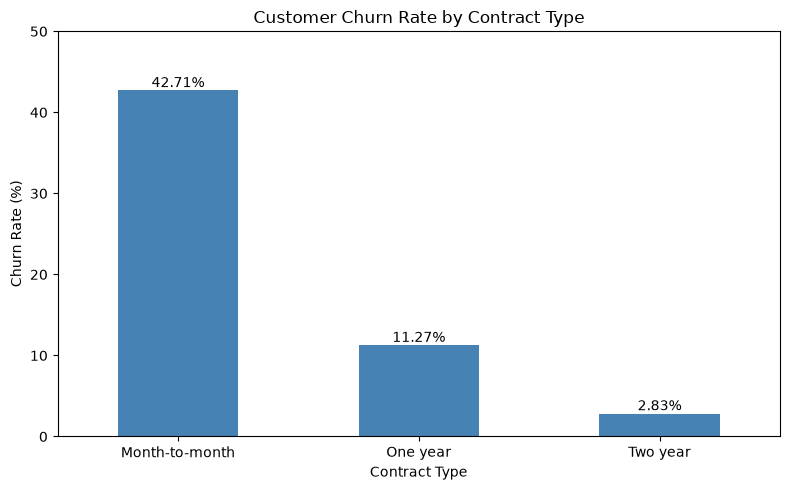

In [8]:
import matplotlib.pyplot as plt

# Calculate churn percentages directly from our dataset
churn_rates = (
    df.groupby("Contract")["Churn"]
    .apply(lambda group: (group == "Yes").mean() * 100)
)

# Create the bar chart
ax = churn_rates.plot(
    kind="bar",
    color="steelblue",
    figsize=(8, 5)
)

# Add a title and labels
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

# Display the percentage above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.ylim(0, 50)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Finding 1: Customer Churn by Contract Type

**Objective:** Determine whether customer churn rates differ across contract types.

**Analysis:** The dataset shows that 42.71% of month-to-month customers canceled their service, compared with 11.27% of one-year contract customers and 2.83% of two-year contract customers.

**Key Finding:** Month-to-month customers have the highest observed churn rate, approximately 15 times higher than customers with two-year contracts.

**Business Implication:** Telecommunications companies could investigate month-to-month customers as a priority segment for retention analysis. Understanding their billing charges, tenure, and service characteristics may help identify opportunities to reduce cancellations.

**Limitation:** These findings show an association between contract type and churn. They do not establish that contract length directly causes customers to stay or cancel.

In [9]:
df["MonthlyCharges"].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

In [10]:
average_charges_by_churn = df.groupby("Churn")["MonthlyCharges"].mean()

print(average_charges_by_churn)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


### Finding 2: Monthly Charges and Customer Churn

**Objective:** Examine whether average monthly charges differ between customers who stayed and customers who canceled their telecommunications service.

**Analysis:** Customers who canceled had an average monthly charge of USD 74.44, compared with USD 61.27 for customers who remained. This represents a difference of approximately USD 13.18 per month, or 21.5%.

**Key Finding:** Customers who canceled paid higher monthly charges on average than customers who stayed.

**Business Implication:** Monthly charges may be a useful variable when identifying customers at risk of cancellation. Telecommunications companies could investigate whether certain pricing levels, service packages, or billing characteristics are associated with higher churn.

**Limitation:** This analysis demonstrates an association between monthly charges and churn. It does not establish that higher prices cause cancellation. Additional analysis is needed to account for contract type, tenure, and other customer characteristics.

In [11]:
charges_by_contract = (
    df.groupby(["Contract", "Churn"])["MonthlyCharges"]
    .mean()
    .round(2)
)

print(charges_by_contract)

Contract        Churn
Month-to-month  No       61.46
                Yes      73.02
One year        No       62.51
                Yes      85.05
Two year        No       60.01
                Yes      86.78
Name: MonthlyCharges, dtype: float64


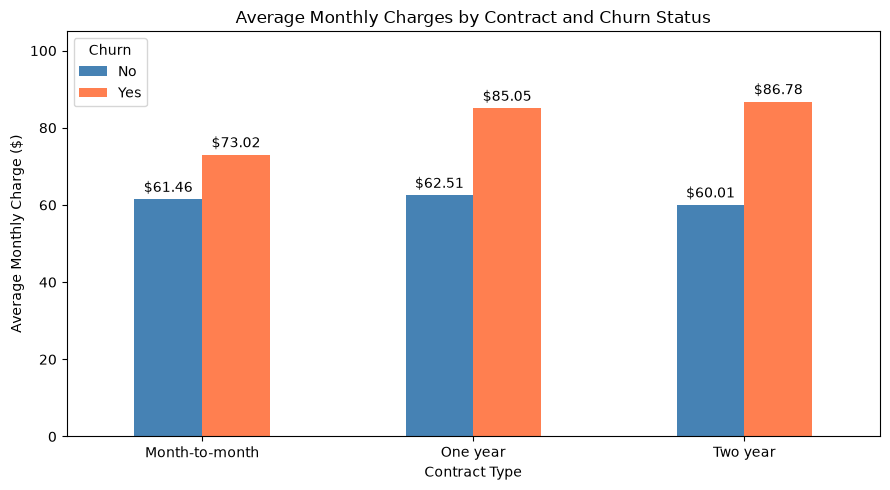

In [12]:
# Calculate average charges. by contract and churn
charges_by_contract = (
    df.groupby(["Contract", "Churn"])["MonthlyCharges"]
    .mean()
    .unstack()
)

# Create a grouped bar chart
ax = charges_by_contract.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "coral"]
)

# Labels for graph
ax.set_title("Average Monthly Charges by Contract and Churn Status")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Average Monthly Charge ($)")
ax.legend(title="Churn")

# Display dollar amounts above bars
for container in ax.containers:
    ax.bar_label(container, fmt="$%.2f", padding=3)

    plt.xticks(rotation=0)
    plt.ylim(0,105)
    plt.tight_layout()
    plt.show

### Finding 3: Monthly Charges, Contract Type, and Customer Churn

**Objective:** Examine whether the relationship between monthly charges and customer churn remains visible across different contract types.

**Analysis:** Customers who canceled their service had higher average monthly charges in all three contract categories. The difference was $11.56 for month-to-month customers, $22.54 for one-year contract customers, and $26.77 for two-year contract customers.

**Key Finding:** Higher monthly charges are associated with customer churn even when customers are grouped by contract type. The largest difference in average charges occurred among two-year contract customers.

**Business Implication:** Telecommunications companies could investigate whether certain pricing levels or service packages are associated with higher cancellation risk. Contract type and monthly charges may both be useful features in a predictive churn model.

**Limitations:** These results establish associations rather than causal relationships. The number of customers who canceled within each contract category also differs, and other characteristics such as tenure and service type may influence the results. Further analysis is needed before making retention recommendations.

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [14]:
df["TotalCharges"].map(type).value_counts()

TotalCharges
<class 'str'>    7043
Name: count, dtype: int64

In [15]:
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(total_charges_numeric.isna().sum())

11


In [16]:
missing_charges = df[total_charges_numeric.isna()]

missing_charges [
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [17]:
# Convert TotalCharges from strings into numbers
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Replace missing TotalCharges values with zero
df["TotalCharges"] = df["TotalCharges"].fillna(0)

#Verify the data type and remaining missing values
print(df["TotalCharges"].dtype)
print(df["TotalCharges"].isna().sum())

float64
0


In [18]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [19]:
duplicate_customers = df["customerID"].duplicated().sum()

print(duplicate_customers)

0


### Data Cleaning and Validation

**Objective:** Assess and prepare the telecommunications customer dataset for statistical analysis and machine learning.

**Data Type Correction:** The `TotalCharges` column initially contained 7,043 string values instead of numerical values. The column was converted to a numeric data type using pandas.

**Missing Values:** During conversion, 11 records contained blank values in `TotalCharges`. Investigation showed that all 11 customers had zero months of tenure. These missing values were replaced with zero under the assumption that these customers had not yet accumulated service charges.

**Duplicate Records:** The `customerID` column was checked for duplicates. No duplicate customer IDs were identified.

**Validation:** After cleaning, all 21 columns contained zero missing values recognized by pandas, and `TotalCharges` was stored as a numerical variable.

**Limitations:** Replacing missing total charges with zero is an assumption based on customer tenure, not independently verified billing history. Additional validation may be necessary before using the data in a production system.

In [20]:
y = df["Churn"]

print(y.head())

0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: str


In [21]:
X = df[["tenure", "MonthlyCharges", "Contract", "InternetService"]]

print(X.head())

   tenure  MonthlyCharges        Contract InternetService
0       1           29.85  Month-to-month             DSL
1      34           56.95        One year             DSL
2       2           53.85  Month-to-month             DSL
3      45           42.30        One year             DSL
4       2           70.70  Month-to-month     Fiber optic


In [22]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 4)
Target shape: (7043,)


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))

Training customers: 5634
Testing customers: 1409


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical features
categorical_features = ["Contract", "InternetService"]
numerical_features = ["tenure", "MonthlyCharges"]

# Create the preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

print("Preprocessing transformer created successfully!")

Preprocessing transformer created successfully!


In [25]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create our machine learning pipeline
churn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

print("Logistic regression pipeline created successfully!")

Logistic regression pipeline created successfully!


In [26]:
# Train the logistic regression model
churn_model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [27]:
# Predict churn for customers in our test dataset
y_pred = churn_model.predict(X_test)

# Display the first 10 predictions
print(y_pred[:10])

['No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'No']


In [28]:
from sklearn.metrics import accuracy_score

# Compare model predictions against actual churn outcomes
accuracy = accuracy_score(y_test, y_pred)

# Display accuracy as a percentage
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 77.43%


In [29]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

print(cm)

[[912 123]
 [195 179]]


In [30]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        labels=["No", "Yes"]
    )
)

              precision    recall  f1-score   support

          No       0.82      0.88      0.85      1035
         Yes       0.59      0.48      0.53       374

    accuracy                           0.77      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.76      0.77      0.77      1409



In [31]:
# Get predicted probabilities for customer churn
churn_probabilities = churn_model.predict_proba(X_test)[:, 1]

# Display the first 10 probabilities
print(churn_probabilities[:10])

[0.05013022 0.67503481 0.0855107  0.57317589 0.01558568 0.57927521
 0.57833328 0.12618654 0.00659105 0.29166212]


In [32]:
# Predictions using a 30% threshold
y_pred_30 = [
    "Yes" if probability >= 0.30 else "No"
    for probability in churn_probabilities
]

# Evaluate the new predictions
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_30,
    labels=["No", "Yes"]
))

              precision    recall  f1-score   support

          No       0.90      0.74      0.81      1035
         Yes       0.52      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



In [33]:
from sklearn.metrics import confusion_matrix

cm_30 = confusion_matrix(
    y_test,
    y_pred_30,
    labels=["No", "Yes"]
)

print(cm_30)

[[762 273]
 [ 82 292]]


### Model Development and Evaluation

**Objective:** Develop a classification model capable of identifying telecommunications customers at risk of cancellation.

**Initial Model:** A logistic regression model was trained using customer tenure, monthly charges, contract type, and internet service.

**Initial Performance:** At the default 50% classification threshold, the model achieved 77.43% accuracy, 59.27% precision, and 47.86% recall for customer churn.

**Threshold Investigation:** The prediction threshold was reduced from 50% to 30% to examine whether more customers who canceled could be identified.

At the 30% threshold, churn recall increased to 78.07%, while precision decreased to 51.68%. The model identified 113 additional customers who canceled but generated 150 additional false-positive predictions.

**Interpretation:** Lowering the classification threshold improved the model's ability to identify cancellations, but increased the number of customers incorrectly classified as at risk.

**Evaluation Limitation:** These initial threshold comparisons were performed using the test dataset. They are exploratory results, not an unbiased final evaluation of a selected threshold. Further model development will use separate validation data to guide decisions.

**Next Steps:** Compare additional prediction thresholds and model configurations using validation data, then perform a final evaluation using a clearly defined testing procedure.

In [34]:
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Training records:", len(X_train_new))
print("Validation records:", len(X_val))
print("Test records:", len(X_test))

Training records: 4225
Validation records: 1409
Test records: 1409


In [35]:
from sklearn.base import clone

# Fresh copy of original pipeline
validated_model = clone(churn_model)

# Train using only the new training dataset
validated_model.fit(X_train_new, y_train_new)

print("Validation model trained successfully!")

Validation model trained successfully!


In [36]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Predict churn probabilities for validation customers
val_probabilities = validated_model.predict_proba(X_val)[:, 1]

# Compare different prediction thresholds
thresholds = [0.30, 0.40, 0.50]

for threshold in thresholds:
    predictions = [
        "Yes" if probability >= threshold else "No"
        for probability in val_probabilities
    ]

    precision = precision_score(
        y_val, predictions, pos_label="Yes"
    )

    recall = recall_score(
        y_val, predictions, pos_label="Yes"
    )

    f1 = f1_score(
        y_val, predictions, pos_label="Yes"
    )

    print(f"Threshold: {threshold:.0%}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall: {recall:.2%}")
    print(f"F1-score: {f1:.2%}")
    print()

Threshold: 30%
Precision: 51.60%
Recall: 77.54%
F1-score: 61.97%



Threshold: 40%
Precision: 59.95%
Recall: 66.04%
F1-score: 62.85%

Threshold: 50%
Precision: 65.71%
Recall: 49.20%
F1-score: 56.27%



In [37]:
# Select the best F1 threshold from our validation comparison
selected_threshold = 0.40

# Generate validation predictions using the selected threshold
val_predictions = [
    "Yes" if probability >= selected_threshold else "No"
    for probability in val_probabilities
]

# Confirm the selected threshold's F1-score
selected_f1 = f1_score(
    y_val,
    val_predictions,
    pos_label="Yes"
)

print(f"Selected threshold: {selected_threshold:.0%}")
print(f"Validation F1-score: {selected_f1:.2%}")

Selected threshold: 40%
Validation F1-score: 62.85%


In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Create the random forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            min_samples_leaf=5
        ))
    ]
)

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [39]:
from sklearn.utils.validation import check_is_fitted

try:
    check_is_fitted(random_forest_model)
    print("Random Forest is trained.")
except Exception as error:
    print(type(error).__name__)
    print("Random Forest needs to be trained.")

NotFittedError
Random Forest needs to be trained.


In [40]:
# Train the Random Forest model
random_forest_model.fit(X_train_new, y_train_new)

# Verify that training was successful
from sklearn.utils.validation import check_is_fitted

check_is_fitted(random_forest_model)

print("Random Forest is trained and ready!")

Random Forest is trained and ready!


In [41]:
from sklearn.metrics import classification_report

# Predict churn for validation customers
rf_predictions = random_forest_model.predict(X_val)

# Evaluate prediction performance
print(classification_report(
    y_val,
    rf_predictions,
    labels=["No", "Yes"]
))

              precision    recall  f1-score   support

          No       0.82      0.90      0.86      1035
         Yes       0.62      0.46      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409



In [42]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Generate Random Forest churn probabilities
rf_probabilities = random_forest_model.predict_proba(X_val)[:, 1]

# Compare classification thresholds
thresholds = [0.30, 0.40, 0.50]

for threshold in thresholds:
    rf_pred_threshold = [
        "Yes" if probability >= threshold else "No"
        for probability in rf_probabilities
    ]

    precision = precision_score(
        y_val, rf_pred_threshold, pos_label="Yes"
    )

    recall = recall_score(
        y_val, rf_pred_threshold, pos_label="Yes"
    )

    f1 = f1_score(
        y_val, rf_pred_threshold, pos_label="Yes"
    )

    print(f"Threshold: {threshold:.0%}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall: {recall:.2%}")
    print(f"F1-score: {f1:.2%}")
    print()

Threshold: 30%
Precision: 53.50%
Recall: 75.67%
F1-score: 62.68%

Threshold: 40%
Precision: 58.29%
Recall: 60.16%
F1-score: 59.21%

Threshold: 50%
Precision: 62.18%
Recall: 45.72%
F1-score: 52.70%



### Model Comparison and Validation Results

**Objective:** Compare Logistic Regression and Random Forest to identify an effective classification approach for predicting telecommunications customer churn.

**Methodology:** Both models were trained using 4,225 customer records and evaluated on a separate validation dataset containing 1,409 customers. Classification thresholds of 30%, 40%, and 50% were compared using precision, recall, and F1-score.

**Logistic Regression:** The highest validation F1-score was 62.85% at a 40% threshold, with precision of 59.95% and recall of 66.04%.

**Random Forest:** The highest validation F1-score was 62.68% at a 30% threshold, with precision of 53.50% and recall of 75.67%.

**Key Finding:** Logistic Regression achieved a marginally higher validation F1-score, while Random Forest identified a greater proportion of actual cancellations at its selected threshold.

**Provisional Model Selection:** Logistic Regression with a 40% classification threshold was selected based on its slightly higher validation F1-score. Random Forest remains a competitive alternative when higher recall is prioritized.

**Limitations:** These results depend on the selected dataset, features, and validation split. The original test dataset was examined during earlier exploratory experiments and therefore cannot be considered completely untouched. The observed performance differences do not establish that either model will consistently outperform the other on future customers.

In [43]:
from sklearn.base import clone

# Create a new copy of the selected logistic regression pipeline
final_model = clone(validated_model)

# Retrain on the combined training and validation data
final_model.fit(X_train, y_train)

print("Final Logistic Regression model trained successfully!")
print("Training records:", len(X_train))

Final Logistic Regression model trained successfully!
Training records: 5634


In [44]:
print("Jupyter is working!")

Jupyter is working!


In [45]:
from pathlib import Path

print("Current working directory:", Path.cwd())
print("Dataset found:", Path("data/Telco-Customer-Churn.csv").exists())
print("Saved model found:", Path("models/churn_logistic_regression.joblib").exists())

Current working directory: /Users/andresjacque/Desktop/Data Science Projects/telecom-customer-churn
Dataset found: True
Saved model found: True


In [46]:
import joblib
import pandas as pd

# Load the saved model package
saved_package = joblib.load(
    "models/churn_logistic_regression.joblib"
)

model = saved_package["model"]
threshold = saved_package["threshold"]

# Load one customer from the dataset
customer = pd.read_csv(
    "data/Telco-Customer-Churn.csv"
).head(1)

# Select the four model features
customer = customer[saved_package["features"]]

# Predict churn probability
churn_probability = model.predict_proba(customer)[0, 1]

# Apply our selected threshold
prediction = "Yes" if churn_probability >= threshold else "No"

print(f"Churn probability: {churn_probability:.2%}")
print("Predicted churn:", prediction)
print(f"Classification threshold: {threshold:.0%}")

Churn probability: 38.53%
Predicted churn: No
Classification threshold: 40%
